In [1]:
import pandas as pd
import numpy as np
import torch

from pathlib import Path
from sklearn.preprocessing import LabelEncoder

# Reproducibilidad
SEMILLA = 42

torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)

# Buscar el dataset
carpeta = Path("data")

if not carpeta.exists():
    carpeta = Path("../data")

df = pd.read_csv(
    carpeta / "SGSST_auditorias_sinteticas_5000.csv"
)

# Mantener las particiones originales
train = df[df["split"] == "train"].copy()
val = df[df["split"] == "val"].copy()

# No utilizaremos test para ajustar el modelo

encoder = LabelEncoder()
encoder.fit(train["categoria"])

y_train = encoder.transform(train["categoria"])
y_val = encoder.transform(val["categoria"])

num_clases = len(encoder.classes_)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Dispositivo:", device)
print("Entrenamiento:", len(train))
print("Validación:", len(val))
print("Categorías:", num_clases)

Dispositivo: cuda
Entrenamiento: 3752
Validación: 624
Categorías: 12


In [2]:
import re
from collections import Counter

def tokenizar(texto):
    texto = str(texto).lower()

    # Conservar letras, números y caracteres en español
    return re.findall(
        r"[a-záéíóúüñ0-9]+",
        texto
    )

# Contar palabras del entrenamiento
contador = Counter()

for texto in train["hallazgo"]:
    contador.update(tokenizar(texto))

# Tokens especiales
PAD = 0
UNK = 1

vocabulario = {
    "<PAD>": PAD,
    "<UNK>": UNK
}

# Crear vocabulario usando solo entrenamiento
for palabra, frecuencia in contador.items():

    if frecuencia >= 2:
        vocabulario[palabra] = len(vocabulario)

print("Tamaño del vocabulario:", len(vocabulario))

print("\nEjemplo de tokenización:")

ejemplo = train["hallazgo"].iloc[0]

print("Texto:", ejemplo)
print("Tokens:", tokenizar(ejemplo))

Tamaño del vocabulario: 343

Ejemplo de tokenización:
Texto: El equipo auditor documento la siguiente situacion: no hay seguimiento a un hallazgo del proveedor; se requiere seguimiento.
Tokens: ['el', 'equipo', 'auditor', 'documento', 'la', 'siguiente', 'situacion', 'no', 'hay', 'seguimiento', 'a', 'un', 'hallazgo', 'del', 'proveedor', 'se', 'requiere', 'seguimiento']


In [3]:
MAX_LENGTH = 48

def codificar_texto(texto):

    tokens = tokenizar(texto)

    ids = [
        vocabulario.get(token, UNK)
        for token in tokens[:MAX_LENGTH]
    ]

    # Completar con padding
    if len(ids) < MAX_LENGTH:
        ids += [PAD] * (MAX_LENGTH - len(ids))

    return ids


X_train = np.array([
    codificar_texto(texto)
    for texto in train["hallazgo"]
])

X_val = np.array([
    codificar_texto(texto)
    for texto in val["hallazgo"]
])

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)

print("\nPrimer texto convertido a números:")
print(X_train[0])

Entrenamiento: (3752, 48)
Validación: (624, 48)

Primer texto convertido a números:
[ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 11  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]


In [4]:
def calcular_desconocidos(textos):

    total_tokens = 0
    desconocidos = 0

    for texto in textos:

        tokens = tokenizar(texto)[:MAX_LENGTH]

        total_tokens += len(tokens)

        desconocidos += sum(
            token not in vocabulario
            for token in tokens
        )

    porcentaje = (
        desconocidos / total_tokens * 100
        if total_tokens > 0 else 0
    )

    return porcentaje


unk_train = calcular_desconocidos(
    train["hallazgo"]
)

unk_val = calcular_desconocidos(
    val["hallazgo"]
)

print(
    "Tokens desconocidos en entrenamiento:",
    f"{unk_train:.2f}%"
)

print(
    "Tokens desconocidos en validación:",
    f"{unk_val:.2f}%"
)

Tokens desconocidos en entrenamiento: 0.00%
Tokens desconocidos en validación: 14.95%


In [5]:
from torch.utils.data import TensorDataset, DataLoader

# Convertir datos a tensores
X_train_tensor = torch.tensor(
    X_train, dtype=torch.long
)

y_train_tensor = torch.tensor(
    y_train, dtype=torch.long
)

X_val_tensor = torch.tensor(
    X_val, dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_val, dtype=torch.long
)

# Crear datasets
dataset_train = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

dataset_val = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

# Crear lotes
loader_train = DataLoader(
    dataset_train,
    batch_size=32,
    shuffle=True
)

loader_val = DataLoader(
    dataset_val,
    batch_size=64,
    shuffle=False
)

print("Lotes de entrenamiento:", len(loader_train))
print("Lotes de validación:", len(loader_val))

Lotes de entrenamiento: 118
Lotes de validación: 10


In [6]:
import torch.nn as nn

class MiniTransformerSST(nn.Module):

    def __init__(
        self,
        vocab_size,
        num_clases,
        max_length=48,
        d_model=128,
        nhead=4,
        num_layers=2
    ):
        super().__init__()

        # Representación de palabras
        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=PAD
        )

        # Representación de posiciones
        self.posicion = nn.Embedding(
            max_length,
            d_model
        )

        # Capa Transformer
        capa_encoder = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=256,
            dropout=0.2,
            activation="gelu",
            batch_first=True
        )

        # Dos capas Transformer
        self.transformer = nn.TransformerEncoder(
            capa_encoder,
            num_layers=num_layers,
            enable_nested_tensor=False
        )

        self.dropout = nn.Dropout(0.2)

        # Clasificador final
        self.clasificador = nn.Linear(
            d_model,
            num_clases
        )

    def forward(self, input_ids):

        batch_size, longitud = input_ids.shape

        # Máscara: True donde hay relleno
        mascara_padding = input_ids.eq(PAD)

        posiciones = torch.arange(
            longitud,
            device=input_ids.device
        ).unsqueeze(0)

        # Embeddings de palabras y posiciones
        x = (
            self.embedding(input_ids)
            + self.posicion(posiciones)
        )

        # Atención multi-cabeza
        x = self.transformer(
            x,
            src_key_padding_mask=mascara_padding
        )

        # Promedio ignorando padding
        mascara_valida = (~mascara_padding).unsqueeze(-1)

        suma = (
            x * mascara_valida
        ).sum(dim=1)

        cantidad = mascara_valida.sum(
            dim=1
        ).clamp(min=1)

        representacion = suma / cantidad

        # Clasificación
        representacion = self.dropout(representacion)

        logits = self.clasificador(
            representacion
        )

        return logits


modelo_propio = MiniTransformerSST(
    vocab_size=len(vocabulario),
    num_clases=num_clases,
    max_length=MAX_LENGTH
).to(device)

print("Mini-Transformer creado correctamente")

parametros = sum(
    p.numel()
    for p in modelo_propio.parameters()
)

print(f"Parámetros totales: {parametros:,}")

Mini-Transformer creado correctamente
Parámetros totales: 316,556


In [7]:
# Obtener un lote
batch_textos, batch_etiquetas = next(
    iter(loader_train)
)

batch_textos = batch_textos.to(device)

modelo_propio.eval()

with torch.no_grad():

    salidas = modelo_propio(
        batch_textos
    )

print("Forma de entrada:", batch_textos.shape)

print("Forma de salida:", salidas.shape)

print("Primeras predicciones:")

print(
    torch.argmax(
        salidas,
        dim=1
    )[:10].cpu().numpy()
)

Forma de entrada: torch.Size([32, 48])
Forma de salida: torch.Size([32, 12])
Primeras predicciones:
[ 4  3 11 10 10  4  4  9 11 10]


In [8]:
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score

# Función que mide el error
criterio = nn.CrossEntropyLoss()

# Optimizador
optimizador = AdamW(
    modelo_propio.parameters(),
    lr=0.0003,
    weight_decay=0.01
)

# Configuración
EPOCAS = 20
PACIENCIA = 4

print("Entrenamiento configurado")
print("Épocas máximas:", EPOCAS)
print("Learning rate:", 0.0003)
print("Early stopping:", PACIENCIA)

Entrenamiento configurado
Épocas máximas: 20
Learning rate: 0.0003
Early stopping: 4


In [9]:
import copy

historial = {
    "train_loss": [],
    "val_accuracy": [],
    "val_f1": []
}

mejor_f1 = -1.0
mejor_epoca = 0
mejores_pesos = None
epocas_sin_mejora = 0

for epoca in range(EPOCAS):

    # ENTRENAMIENTO
    modelo_propio.train()

    perdida_total = 0
    total_registros = 0

    for textos, etiquetas in loader_train:

        textos = textos.to(device)
        etiquetas = etiquetas.to(device)

        optimizador.zero_grad()

        # Predicción
        salidas = modelo_propio(textos)

        # Calcular pérdida
        perdida = criterio(salidas, etiquetas)

        # Backpropagation
        perdida.backward()

        # Evitar gradientes excesivos
        torch.nn.utils.clip_grad_norm_(
            modelo_propio.parameters(),
            max_norm=1.0
        )

        # Actualizar pesos
        optimizador.step()

        perdida_total += (
            perdida.item() * len(etiquetas)
        )
        total_registros += len(etiquetas)

    train_loss = perdida_total / total_registros

    # VALIDACIÓN
    modelo_propio.eval()

    predicciones = []
    reales = []

    with torch.inference_mode():

        for textos, etiquetas in loader_val:

            textos = textos.to(device)

            salidas = modelo_propio(textos)

            pred = torch.argmax(
                salidas,
                dim=1
            )

            predicciones.extend(
                pred.cpu().tolist()
            )

            reales.extend(
                etiquetas.tolist()
            )

    accuracy = accuracy_score(
        reales,
        predicciones
    )

    macro_f1 = f1_score(
        reales,
        predicciones,
        average="macro",
        zero_division=0
    )

    historial["train_loss"].append(train_loss)
    historial["val_accuracy"].append(accuracy)
    historial["val_f1"].append(macro_f1)

    print(
        f"Época {epoca+1:02d} | "
        f"Loss: {train_loss:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Macro-F1: {macro_f1:.4f}"
    )

    # Guardar el mejor modelo
    if macro_f1 > mejor_f1 + 1e-4:

        mejor_f1 = macro_f1
        mejor_epoca = epoca + 1

        mejores_pesos = copy.deepcopy(
            modelo_propio.state_dict()
        )

        epocas_sin_mejora = 0

    else:
        epocas_sin_mejora += 1

    # Detener si no mejora
    if epocas_sin_mejora >= PACIENCIA:

        print("\nEarly stopping activado")
        break

# Recuperar la mejor versión
modelo_propio.load_state_dict(mejores_pesos)
modelo_propio.eval()

print("\nENTRENAMIENTO FINALIZADO")
print("Mejor época:", mejor_epoca)
print(f"Mejor Macro-F1: {mejor_f1:.4f}")

Época 01 | Loss: 2.1941 | Accuracy: 0.0465 | Macro-F1: 0.0384
Época 02 | Loss: 0.6081 | Accuracy: 0.0721 | Macro-F1: 0.0832
Época 03 | Loss: 0.0442 | Accuracy: 0.0833 | Macro-F1: 0.0866
Época 04 | Loss: 0.0146 | Accuracy: 0.0849 | Macro-F1: 0.0890
Época 05 | Loss: 0.0080 | Accuracy: 0.0897 | Macro-F1: 0.0907
Época 06 | Loss: 0.0055 | Accuracy: 0.0946 | Macro-F1: 0.0940
Época 07 | Loss: 0.0040 | Accuracy: 0.0881 | Macro-F1: 0.0882
Época 08 | Loss: 0.0031 | Accuracy: 0.0978 | Macro-F1: 0.0953
Época 09 | Loss: 0.0024 | Accuracy: 0.0897 | Macro-F1: 0.0892
Época 10 | Loss: 0.0020 | Accuracy: 0.0897 | Macro-F1: 0.0890
Época 11 | Loss: 0.0016 | Accuracy: 0.0978 | Macro-F1: 0.0947
Época 12 | Loss: 0.0014 | Accuracy: 0.0913 | Macro-F1: 0.0909

Early stopping activado

ENTRENAMIENTO FINALIZADO
Mejor época: 8
Mejor Macro-F1: 0.0953


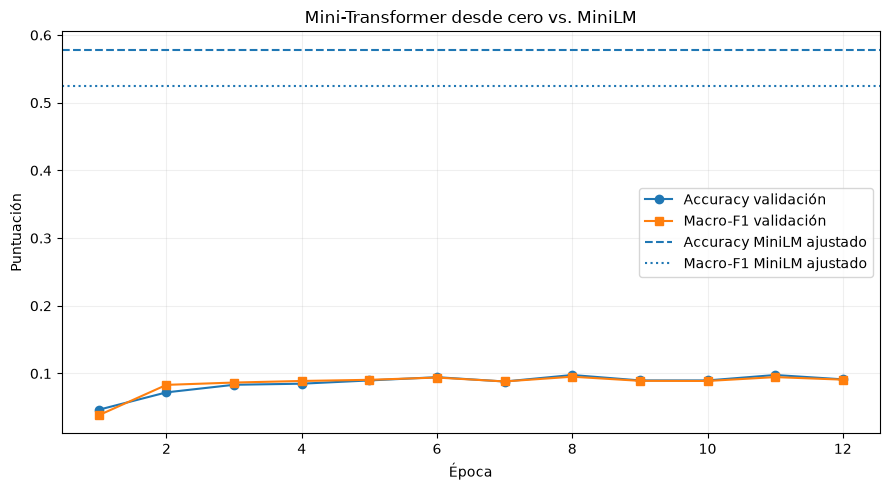

In [10]:
import matplotlib.pyplot as plt

epocas = range(
    1,
    len(historial["val_f1"]) + 1
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    epocas,
    historial["val_accuracy"],
    marker="o",
    label="Accuracy validación"
)

ax.plot(
    epocas,
    historial["val_f1"],
    marker="s",
    label="Macro-F1 validación"
)

# Referencia: MiniLM fine-tuning
ax.axhline(
    0.5785,
    linestyle="--",
    label="Accuracy MiniLM ajustado"
)

ax.axhline(
    0.5253,
    linestyle=":",
    label="Macro-F1 MiniLM ajustado"
)

ax.set_xlabel("Época")
ax.set_ylabel("Puntuación")
ax.set_title(
    "Mini-Transformer desde cero vs. MiniLM"
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [11]:
from pathlib import Path
import json
import torch

ruta_modelo = Path("models/mini_transformer_propio")

if not Path("data").exists():
    ruta_modelo = Path("../models/mini_transformer_propio")

ruta_modelo.mkdir(parents=True, exist_ok=True)

# Guardar los pesos entrenados
torch.save(
    modelo_propio.state_dict(),
    ruta_modelo / "modelo.pth"
)

# Guardar vocabulario y categorías
configuracion = {
    "vocabulario": vocabulario,
    "categorias": encoder.classes_.tolist(),
    "max_length": MAX_LENGTH,
    "d_model": 128,
    "nhead": 4,
    "num_layers": 2,
    "num_clases": num_clases,
    "mejor_epoca": mejor_epoca,
    "mejor_macro_f1_validacion": float(mejor_f1)
}

with open(
    ruta_modelo / "configuracion.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        configuracion,
        archivo,
        ensure_ascii=False,
        indent=4
    )

print("Mini-Transformer guardado correctamente.")
print("Ubicación:", ruta_modelo)

Mini-Transformer guardado correctamente.
Ubicación: ..\models\mini_transformer_propio
